In [1]:
# -o: replace old files without asking, so Run all never stops
!unzip -q -o /content/BTXRD_cyclegan_512.zip -d /content
!ls /content/BTXRD_cyclegan_512

import torch
print("GPU on:", torch.cuda.is_available())

test  train  validation
GPU on: True


In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

device = torch.device("cuda")
DATA = "/content/BTXRD_cyclegan_512"

# put the images in the format ResNet-18 expects (ImageNet format)
to_model_format = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),   # 1 gray channel -> 3 channels
    transforms.ToTensor(),                          # pixels 0-255 -> 0-1
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # ImageNet format
])

# the label of each image is the name of its folder
train_data = datasets.ImageFolder(f"{DATA}/train", transform=to_model_format)
validation_data = datasets.ImageFolder(f"{DATA}/validation", transform=to_model_format)
test_data = datasets.ImageFolder(f"{DATA}/test", transform=to_model_format)

print("Classes:", train_data.classes)
print("Train:", len(train_data), " Validation:", len(validation_data), " Test:", len(test_data))

Classes: ['normal', 'tumor']
Train: 2606  Validation: 558  Test: 559


In [3]:
# settings (change the numbers here)
EPOCHS = 20             # the most rounds through all train images (can stop earlier, see PATIENCE)
BATCH_SIZE = 16         # how many images the model looks at in one step
LEARNING_RATE = 0.0001  # how big each learning step is
PATIENCE = 5            # stop early if the validation loss does not improve for this many rounds in a row
SEED = 42               # makes the random parts the same every time

# make the run repeatable
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True   # same GPU calculations every time
torch.backends.cudnn.benchmark = False

# data in groups of BATCH_SIZE
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
validation_loader = DataLoader(validation_data, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE)

# model: ResNet-18 that already learned from ImageNet
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, 2)   # new last layer with 2 outputs: normal, tumor
model = model.to(device)                        # move the model to the GPU

# loss function and optimizer
loss_function = nn.CrossEntropyLoss()                                 # measures how wrong the answers are
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)    # changes the model a little after each step

print("Model: ResNet-18 | Epochs:", EPOCHS, "| Batch size:", BATCH_SIZE, "| Learning rate:", LEARNING_RATE, "| Patience:", PATIENCE, "| Seed:", SEED)
print("Loss function: CrossEntropy | Optimizer: Adam")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s]


Model: ResNet-18 | Epochs: 20 | Batch size: 16 | Learning rate: 0.0001 | Patience: 5 | Seed: 42
Loss function: CrossEntropy | Optimizer: Adam


In [4]:
best_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0   # rounds in a row where the validation loss did not get better
train_losses, validation_losses = [], []

for epoch in range(1, EPOCHS + 1):

    # learn from the train images
    model.train()
    train_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)                  # the model guesses
        loss = loss_function(outputs, labels)    # how wrong the guesses are
        optimizer.zero_grad()
        loss.backward()                          # find what to change
        optimizer.step()                         # change the model a little
        train_loss += loss.item() * len(labels)
    train_loss = train_loss / len(train_data)

    # check on the validation images (the model does not learn here)
    model.eval()
    validation_loss, correct = 0, 0
    with torch.no_grad():
        for images, labels in validation_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            validation_loss += loss_function(outputs, labels).item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
    validation_loss = validation_loss / len(validation_data)
    validation_accuracy = correct / len(validation_data)

    train_losses.append(train_loss)
    validation_losses.append(validation_loss)

    # keep the best round, not the last one
    saved = ""
    if validation_loss < best_loss:
        best_loss = validation_loss
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(model.state_dict(), "/content/best_resnet18.pt")
        saved = "  <- best so far, saved"
    else:
        epochs_without_improvement += 1

    print(f"Epoch {epoch:2d}: train loss {train_loss:.3f}, validation loss {validation_loss:.3f}, "
          f"validation accuracy {validation_accuracy:.3f}{saved}")

    # early stopping: stop when the validation loss has not improved for PATIENCE rounds in a row
    if epochs_without_improvement == PATIENCE:
        print(f"Early stopping: no improvement for {PATIENCE} epochs in a row.")
        break

print(f"Best epoch: {best_epoch} (validation loss {best_loss:.3f}), this one is used for the test.")

Epoch  1: train loss 0.581, validation loss 0.527, validation accuracy 0.737  <- best so far, saved
Epoch  2: train loss 0.490, validation loss 0.530, validation accuracy 0.738
Epoch  3: train loss 0.408, validation loss 1.072, validation accuracy 0.547
Epoch  4: train loss 0.331, validation loss 0.655, validation accuracy 0.753
Epoch  5: train loss 0.235, validation loss 0.574, validation accuracy 0.733
Epoch  6: train loss 0.181, validation loss 0.701, validation accuracy 0.769
Early stopping: no improvement for 5 epochs in a row.
Best epoch: 1 (validation loss 0.527), this one is used for the test.


In [5]:
from sklearn.metrics import classification_report

# load the best round that was saved during training
model.load_state_dict(torch.load("/content/best_resnet18.pt", map_location=device, weights_only=True))
model.eval()

# the model guesses every test image
true_labels, predicted = [], []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        predicted += outputs.argmax(1).cpu().tolist()   # the class with the highest score
        true_labels += labels.tolist()

print(classification_report(true_labels, predicted, target_names=test_data.classes, digits=3))

              precision    recall  f1-score   support

      normal      0.820     0.618     0.705       280
       tumor      0.693     0.864     0.769       279

    accuracy                          0.741       559
   macro avg      0.756     0.741     0.737       559
weighted avg      0.756     0.741     0.737       559



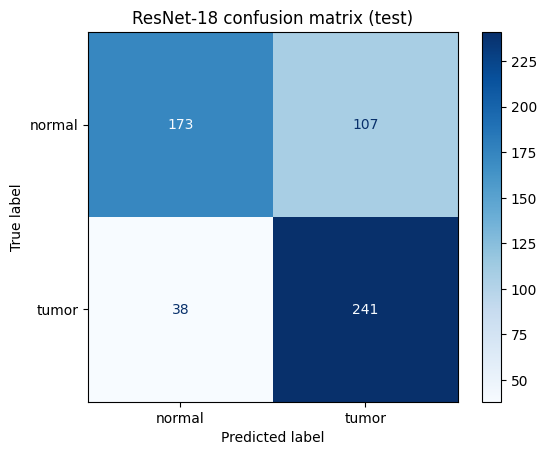

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(true_labels, predicted, display_labels=test_data.classes, cmap="Blues")
plt.title("ResNet-18 confusion matrix (test)")
plt.show()

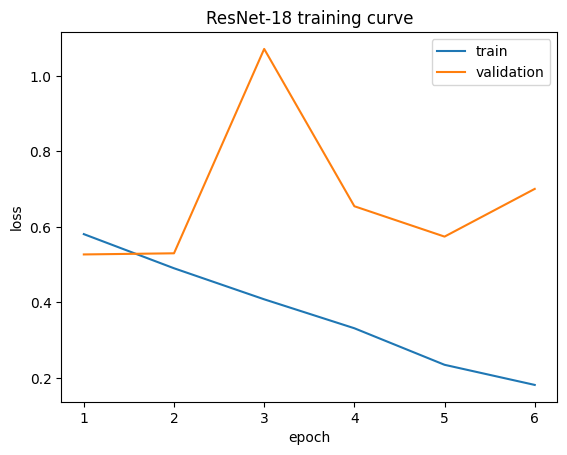

In [7]:
import matplotlib.pyplot as plt

plt.plot(range(1, len(train_losses) + 1), train_losses, label="train")   # may be fewer than EPOCHS after early stopping
plt.plot(range(1, len(validation_losses) + 1), validation_losses, label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("ResNet-18 training curve")
plt.legend()
plt.show()

In [8]:
!pip install -q grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


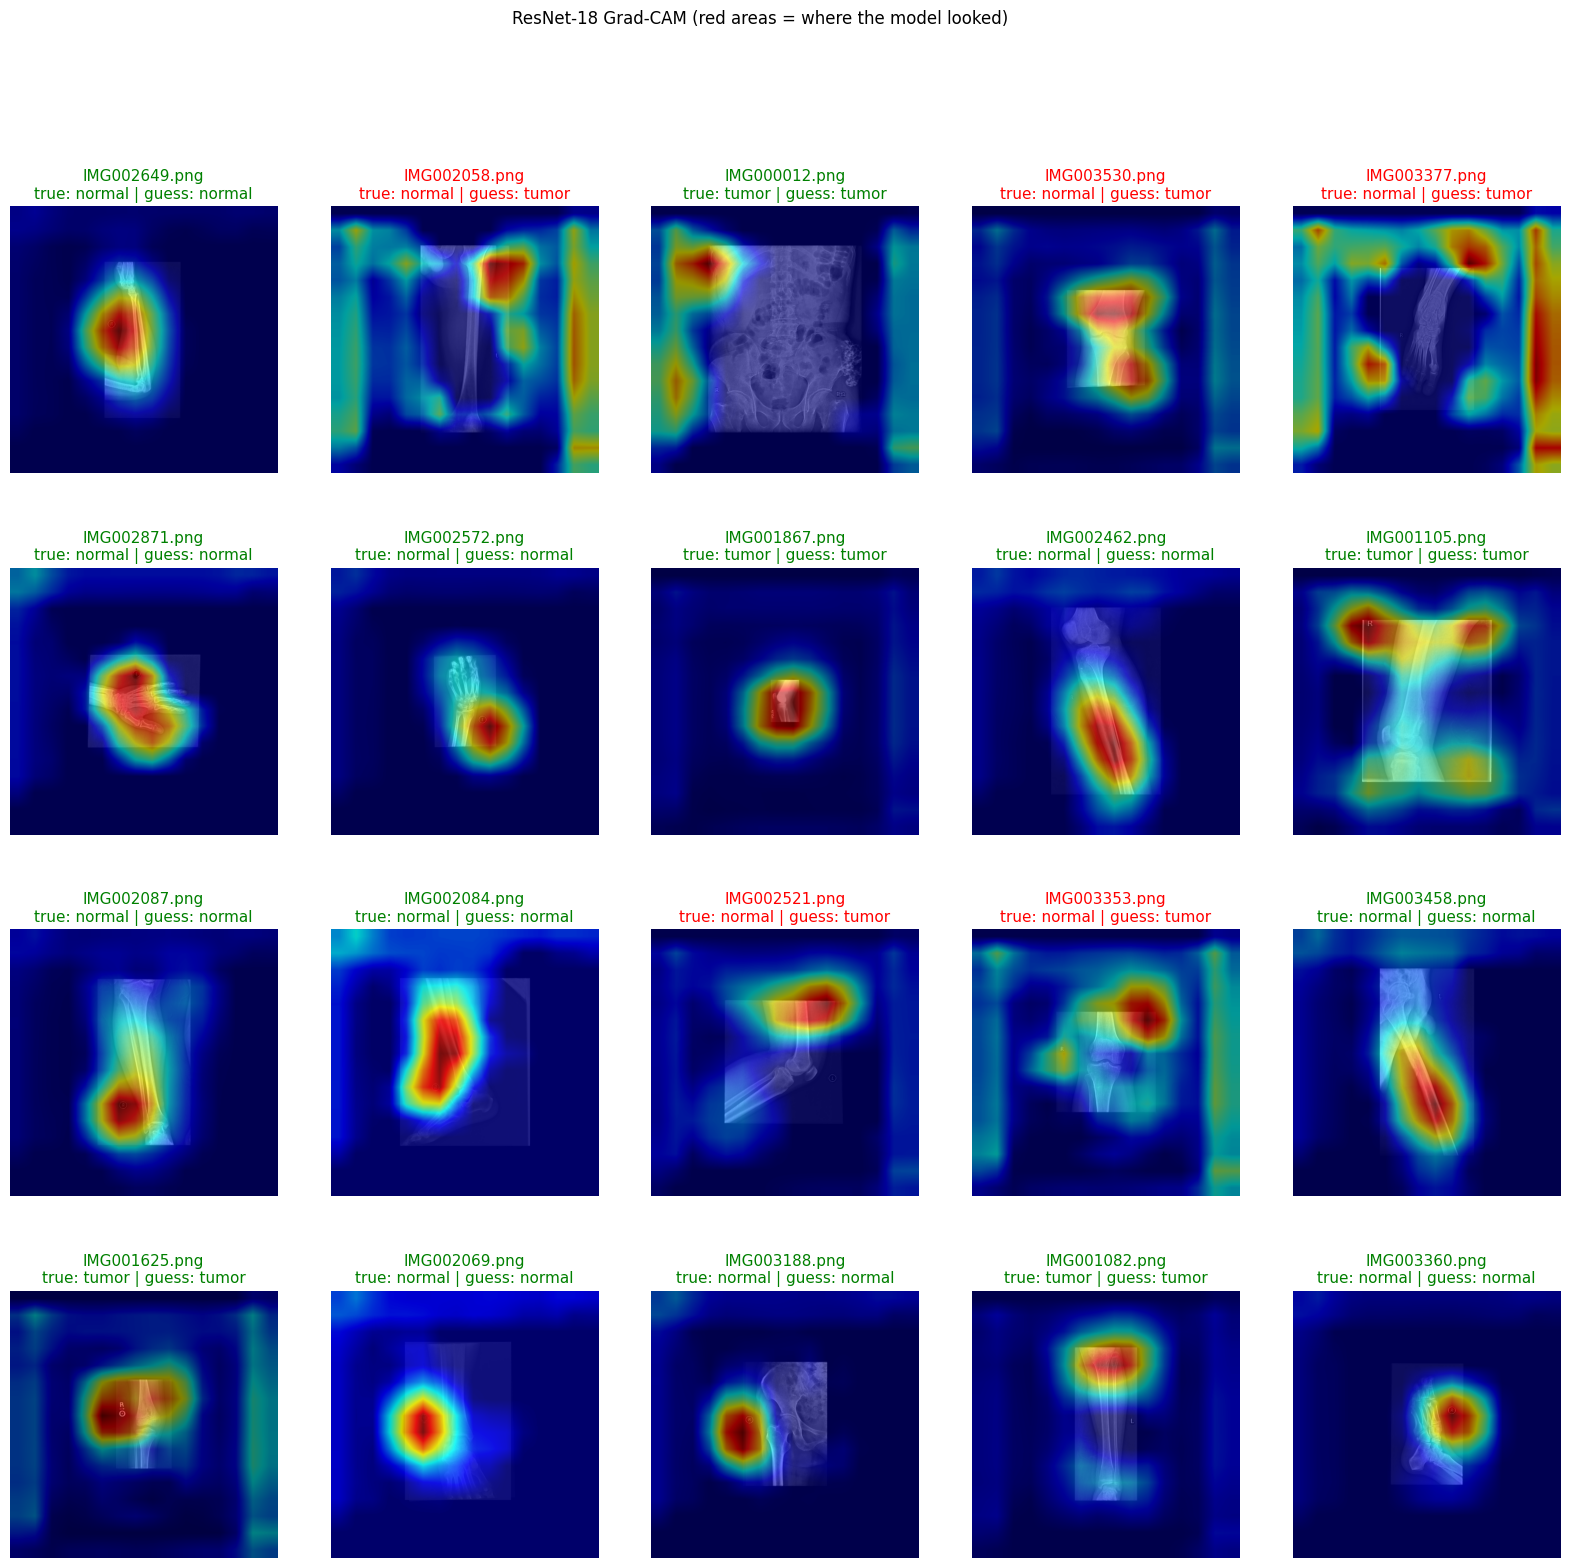

In [13]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget   # NEW

# load the best round that was saved during training
model.load_state_dict(torch.load("/content/best_resnet18.pt", map_location=device, weights_only=True))
model.eval()

# Grad-CAM looks at the last convolution block of ResNet-18
cam = GradCAM(model=model, target_layers=[model.layer4[-1]])

# pick 20 random test images
random.seed(SEED)
picks = random.sample(range(len(test_data)), 20)

# save the names of the 20 picked images, to use the same ones after preprocessing
picked_files = [os.path.relpath(test_data.samples[i][0], DATA) for i in picks]
with open("/content/gradcam_picks.txt", "w") as f:
    f.write("\n".join(picked_files))

plt.figure(figsize=(20, 18))
for n, i in enumerate(picks):
    path = test_data.samples[i][0]                  # the image file
    name = os.path.basename(path)                   # just the file name
    image, label = test_data[i]                     # the image in model format
    image = image.unsqueeze(0).to(device)           # make it a batch of 1 image

    with torch.no_grad():
        guess = model(image).argmax(1).item()       # the model's answer

    heatmap = cam(input_tensor=image, targets=[ClassifierOutputTarget(guess)])[0]   # NEW: explain the model's guess
    original = np.array(test_data.loader(path), dtype=np.float32) / 255   # original image, pixels 0-1
    overlay = show_cam_on_image(original, heatmap, use_rgb=True)          # draw the heatmap on top

    plt.subplot(4, 5, n + 1)
    plt.imshow(overlay)
    plt.title(f"{name}\ntrue: {test_data.classes[label]} | guess: {test_data.classes[guess]}",
              color="green" if guess == label else "red", fontsize=11)
    plt.axis("off")

plt.suptitle("ResNet-18 Grad-CAM (red areas = where the model looked)")
plt.savefig("/content/gradcam_original.png", dpi=150, bbox_inches="tight")   # save the picture
plt.show()

Tumor images guessed as normal: 38


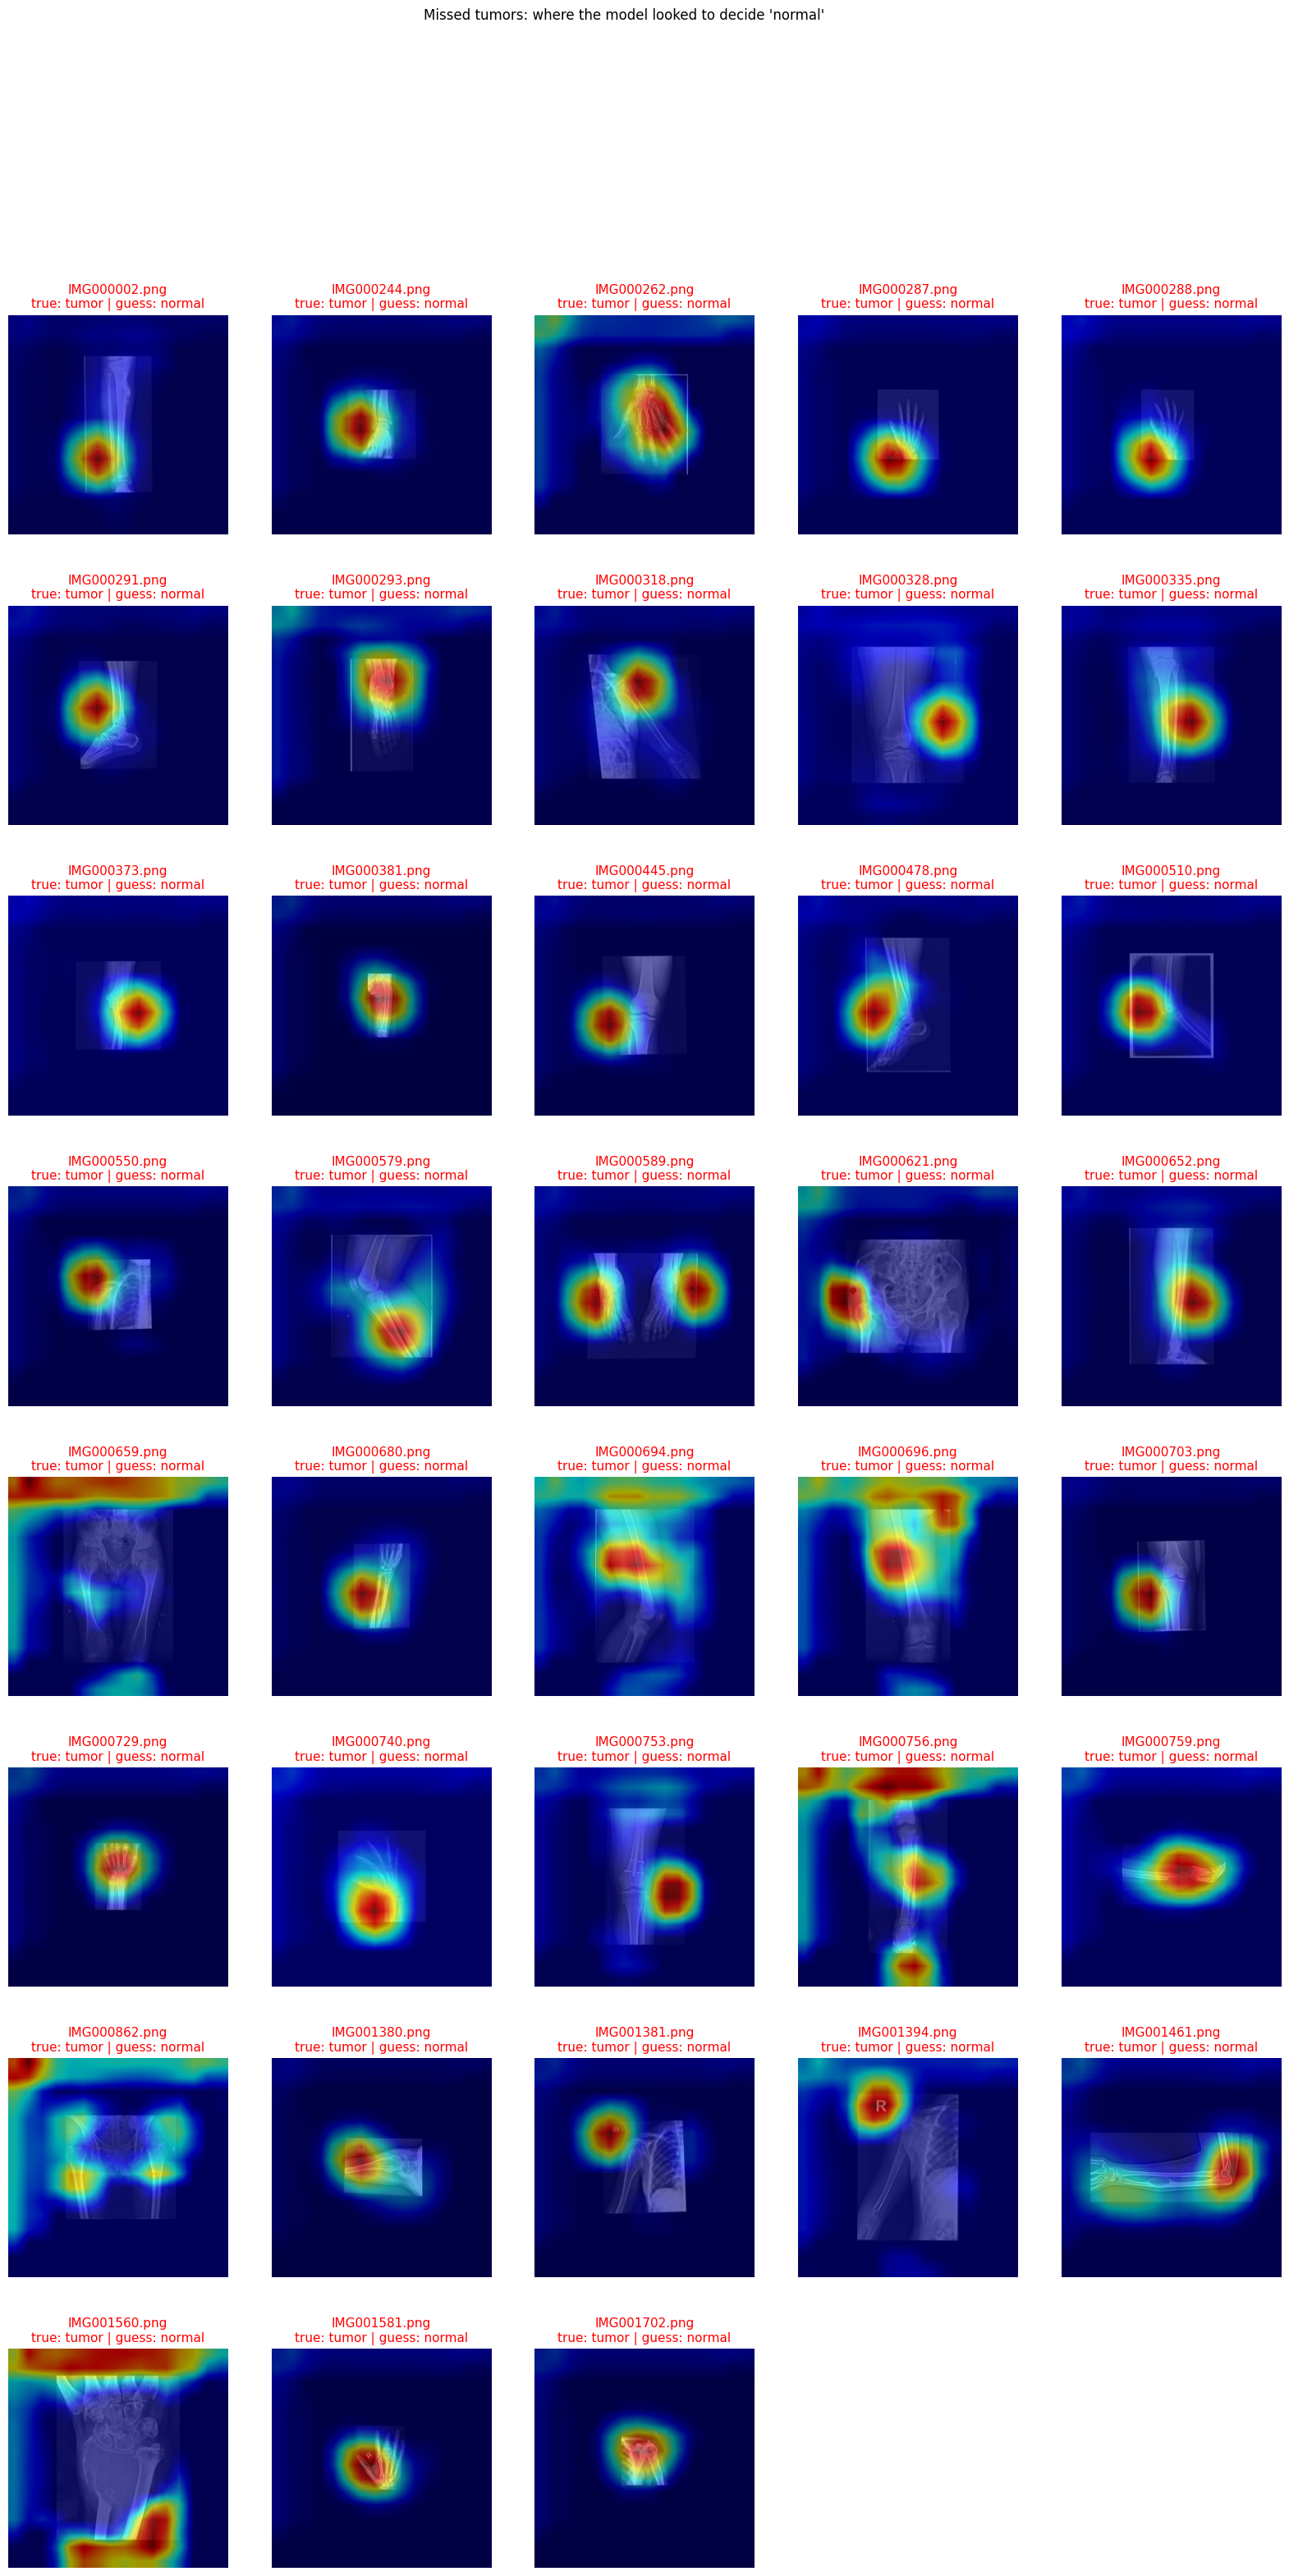

In [10]:
import math

tumor = test_data.classes.index("tumor")     # the number of the tumor class
normal = test_data.classes.index("normal")   # the number of the normal class

# tumor images the model called normal (missed tumors)
missed = [i for i in range(len(test_data)) if true_labels[i] == tumor and predicted[i] == normal]
print("Tumor images guessed as normal:", len(missed))

rows = math.ceil(len(missed) / 5)     # 5 images per row

if missed:
    plt.figure(figsize=(20, 4.5 * rows))
    for n, i in enumerate(missed):
        path = test_data.samples[i][0]              # the image file
        name = os.path.basename(path)               # just the file name
        image, label = test_data[i]                 # the image in model format
        image = image.unsqueeze(0).to(device)       # make it a batch of 1 image

        heatmap = cam(input_tensor=image, targets=[ClassifierOutputTarget(normal)])[0]   # where it looked to say "normal"
        original = np.array(test_data.loader(path), dtype=np.float32) / 255
        overlay = show_cam_on_image(original, heatmap, use_rgb=True)

        plt.subplot(rows, 5, n + 1)
        plt.imshow(overlay)
        plt.title(f"{name}\ntrue: tumor | guess: normal", color="red", fontsize=11)
        plt.axis("off")

    plt.suptitle("Missed tumors: where the model looked to decide 'normal'")
    plt.savefig("/content/gradcam_missed_tumors.png", dpi=150, bbox_inches="tight")
    plt.show()

Normal images guessed as tumor: 107


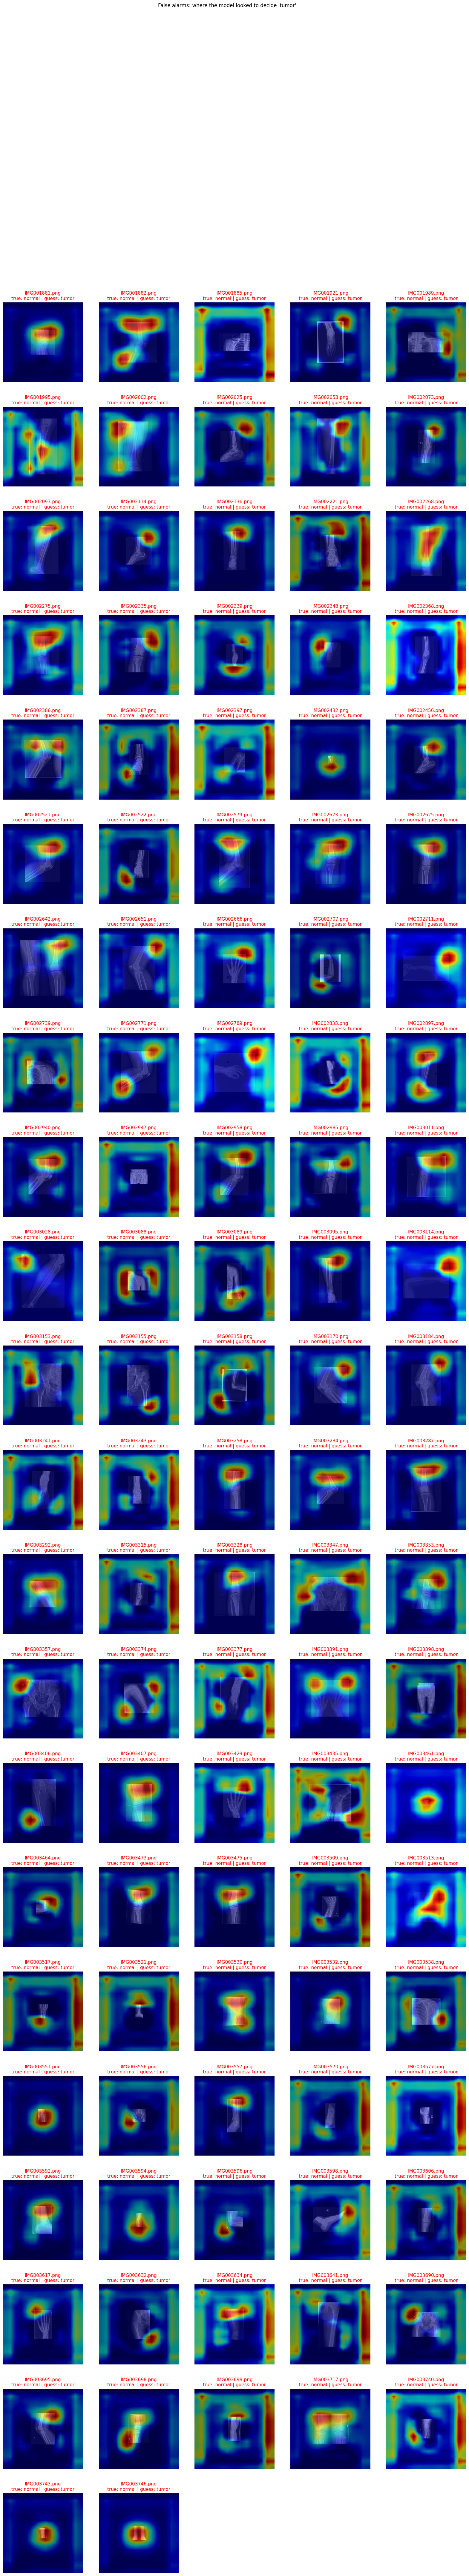

In [14]:
import math

tumor = test_data.classes.index("tumor")     # the number of the tumor class
normal = test_data.classes.index("normal")   # the number of the normal class

# normal images the model called tumor (false alarms)
false_alarms = [i for i in range(len(test_data)) if true_labels[i] == normal and predicted[i] == tumor]
print("Normal images guessed as tumor:", len(false_alarms))

rows = math.ceil(len(false_alarms) / 5)     # 5 images per row

if false_alarms:
    plt.figure(figsize=(20, 4.5 * rows))
    for n, i in enumerate(false_alarms):
        path = test_data.samples[i][0]              # the image file
        name = os.path.basename(path)               # just the file name
        image, label = test_data[i]                 # the image in model format
        image = image.unsqueeze(0).to(device)       # make it a batch of 1 image

        heatmap = cam(input_tensor=image, targets=[ClassifierOutputTarget(tumor)])[0]   # where it looked to say "tumor"
        original = np.array(test_data.loader(path), dtype=np.float32) / 255
        overlay = show_cam_on_image(original, heatmap, use_rgb=True)

        plt.subplot(rows, 5, n + 1)
        plt.imshow(overlay)
        plt.title(f"{name}\ntrue: normal | guess: tumor", color="red", fontsize=11)
        plt.axis("off")

    plt.suptitle("False alarms: where the model looked to decide 'tumor'")
    plt.savefig("/content/gradcam_false_alarms.png", dpi=150, bbox_inches="tight")
    plt.show()

In [12]:
from sklearn.metrics import roc_auc_score

tumor = test_data.classes.index("tumor")   # the number of the tumor class

# how sure the model is that each test image is a tumor (0 to 1)
model.eval()
scores = []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        scores += torch.softmax(outputs, 1)[:, tumor].cpu().tolist()

# AUC: 1.0 = perfect, 0.5 = guessing
print("AUC:", round(roc_auc_score(true_labels, scores), 3))

AUC: 0.852
